# AI651 PA2 · Question 2 · Notebook 1 — Setup, Table 1, Figure 1



Every cell is safe to re-run: the dataset, checkpoints and results are cached on Drive under
`MyDrive/AI651_PA2/`.

In [1]:
# 0) Drive, code and GPU -- run this first in every session
PROJECT = "/content/drive/MyDrive/AI651_PA2"   # data, checkpoints, results, figures live here
UPDATE_CODE = False   # True -> upload pa2_code.zip again (e.g. after you edit a script)

from google.colab import drive
drive.mount("/content/drive")

import os, sys, io, zipfile
CODE_DIR = os.path.join(PROJECT, "code")
os.makedirs(CODE_DIR, exist_ok=True)
if UPDATE_CODE or not os.path.exists(os.path.join(CODE_DIR, "pa2", "__init__.py")):
    from google.colab import files
    print("Upload pa2_code.zip (or the individual pa2/*.py files). "
          "It is stored on Drive, so this is only needed once.")
    for name, blob in files.upload().items():
        if name.endswith(".zip"):
            zipfile.ZipFile(io.BytesIO(blob)).extractall(CODE_DIR)
        elif name.endswith(".py"):
            os.makedirs(os.path.join(CODE_DIR, "pa2"), exist_ok=True)
            clean = name.split(" (")[0].removesuffix(".py") + ".py"   # Colab renames "x (1).py"
            with open(os.path.join(CODE_DIR, "pa2", clean), "wb") as f:
                f.write(blob)
assert os.path.exists(os.path.join(CODE_DIR, "pa2", "__init__.py")), "pa2 package not found on Drive"
if CODE_DIR not in sys.path:
    sys.path.insert(0, CODE_DIR)
for m in [m for m in list(sys.modules) if m == "pa2" or m.startswith("pa2.")]:
    del sys.modules[m]                         # always import the version on Drive

import numpy as np
import matplotlib.pyplot as plt
import pa2
from pa2 import config, data, models, train, evaluation, visuals, checks, tables, utils
from pa2.pipeline import Context
from pa2.utils import show_table
%matplotlib inline
print("pa2 version", pa2.__version__)

Mounted at /content/drive
Upload pa2_code.zip (or the individual pa2/*.py files). It is stored on Drive, so this is only needed once.


Saving pa2_code.zip to pa2_code.zip
pa2 version 1.0


## Data
Videos are split by dataset index: 0–7,999 train, 8,000–8,999 validation, 9,000–9,999 test.

In [2]:
ctx = Context(PROJECT)
ctx.load_data();   # first run: downloads Moving MNIST (~800 MB) to Drive; later runs load it from there

Device: Tesla T4 (15 GB), torch 2.11.0+cu130
Loading Moving MNIST (downloaded to Drive the first time) ...


100%|██████████| 819M/819M [01:07<00:00, 12.1MB/s]


{'train': (8000, 20, 1, 64, 64), 'val': (1000, 20, 1, 64, 64), 'test': (1000, 20, 1, 64, 64)}


In [3]:
x = data.to_unit(ctx.data["test"][:8])
print({k: tuple(v.shape) for k, v in ctx.data.items()}, "| float range after /255:",
      x.dtype, float(x.min()), float(x.max()))

{'train': (8000, 20, 1, 64, 64), 'val': (1000, 20, 1, 64, 64), 'test': (1000, 20, 1, 64, 64)} | float range after /255: torch.float32 0.0 1.0


## Table 1 — implementation checks
Uses exactly the transformation and window functions the experiments call.

In [4]:
rows, ok, md_table = checks.table1(ctx.paths)
show_table(md_table)
assert ok, "Table 1 does not match the handout -- fix this before continuing"

| Check |  | Expected | Yours |
|---|---|---|---|
| (a) | max|M(M(x)) − x| | 0 | 0 (torch.equal: True) |
| (b) | max|R^4(x) − x| | 0 | 0 (torch.equal: True) |
| (c) | max|MRM(x) − R^−1(x)| | 0 | 0 (torch.equal: True) |
| (d) | bright pixel of M(p) (frame, row, column) | (7, 10, 43) | (7, 10, 43) |
| (e) | bright pixel of R(p) (frame, row, column) | (7, 43, 10) | (7, 43, 10) |
| (f) | 1× input / target frames | 1–5 / 6–10 | 1–5 / 6–10 |
| (g) | 2× input / target frames | 1, 3, 5, 7, 9 / 11, 13, 15, 17, 19 | 1, 3, 5, 7, 9 / 11, 13, 15, 17, 19 |
| (h) | 3× input / target frames | 1, 4, 7, 10, 13 / 16, 19 | 1, 4, 7, 10, 13 / 16, 19 |

In [ ]:
nA = models.check_arch_budget("A", is_model_d=False)
print(f"Model A: {nA:,} trainable parameters (handout: 480,784)")

## Figure 1 — is the training data already symmetric?
Farneback flow on the first 50 training videos (950 frame pairs), settings exactly as in the handout.

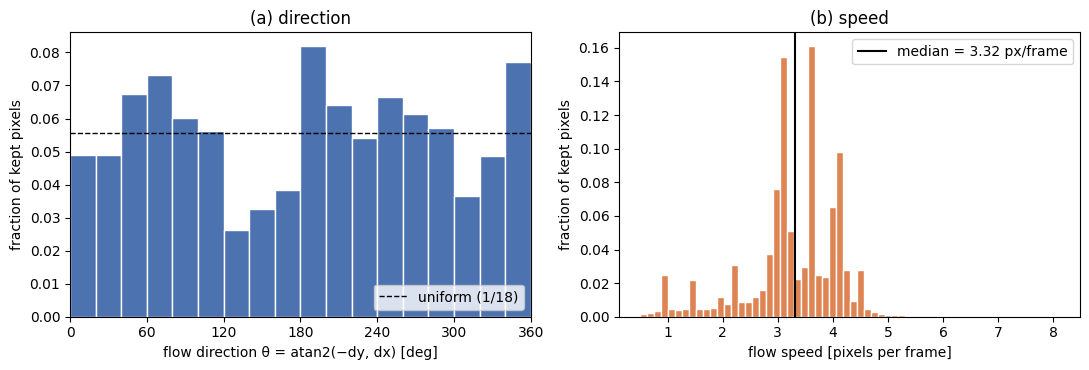

Caption: 103,050 pixels kept from 950 frame pairs; median speed 3.32 px/frame
direction fractions per 20° bin: [0.049  0.0488 0.0675 0.0731 0.0602 0.0561 0.0263 0.0326 0.0384 0.082
 0.0642 0.0541 0.0666 0.0614 0.0571 0.0366 0.0487 0.0772]


In [5]:
angles, speeds = checks.flow_statistics(ctx.data["train"], n_videos=50)
fig1, cap = checks.figure1(ctx.paths, angles, speeds)
utils.atomic_json_save(cap, os.path.join(ctx.paths["results"], "fig1_stats.json"))
plt.show()
print(f"Caption: {cap['n_kept']:,} pixels kept from 950 frame pairs; "
      f"median speed {cap['median_speed']:.3g} px/frame")
frac, edges = np.histogram(angles, bins=np.arange(0, 361, 20))
print("direction fractions per 20° bin:", np.round(frac / frac.sum(), 4))

## Optional smoke test (≈1–2 min)
Trains model A for 20 batches, resumes it for a second short epoch (this exercises the resume
path), and extrapolates the time of a full 30-epoch run. Nothing is written to your project folder.

In [7]:
RUN_SMOKE_TEST = True
SMOKE_BATCHES = 20
if RUN_SMOKE_TEST:
    import shutil
    shutil.rmtree("/content/smoke_test", ignore_errors=True)
    tmp = "/content/smoke_test/A/seed0"
    tr_gpu = ctx.on_device("train")
    train.train_run(tmp, "A", True, True, 0, tr_gpu, ctx.device, epochs=1, max_batches=SMOKE_BATCHES, val_every=0)
    _, info = train.train_run(tmp, "A", True, True, 0, tr_gpu, ctx.device, epochs=2,
                              max_batches=SMOKE_BATCHES, val_every=0)   # resumes at epoch 2
    per_epoch = info["history"][-1]["time_s"] / SMOKE_BATCHES * 250
    print(f"\nModel A on {utils.hardware_string(ctx.device)}: ≈{per_epoch:.0f} s/epoch, "
          f"≈{per_epoch * 30 / 60:.0f} min per 30-epoch run, ≈{per_epoch * 30 * 8 / 3600:.1f} h for "
          "the 8 required runs (model D may be slower or faster depending on the design).")
    shutil.rmtree("/content/smoke_test", ignore_errors=True)

[A/seed0] epoch  1/1  loss 0.11780  0.9 s
[A/seed0] done: 0.9 s/epoch
[A/seed0] resuming at epoch 2, batch 0
[A/seed0] epoch  2/2  loss 0.04249  0.8 s
[A/seed0] done: 0.8 s/epoch

Model A on Tesla T4 (15 GB), torch 2.11.0+cu130: ≈10 s/epoch, ≈5 min per 30-epoch run, ≈0.7 h for the 8 required runs (model D may be slower or faster depending on the design).
